<div style="text-align: center;">

  <img src="img/LogoUesc.png" alt="UESC" style="width: 60px; display: block; margin: 0 auto 5px auto;">

  <div style="font-size: 20px;"><strong>UNIVERSIDADE ESTADUAL DE SANTA CRUZ - UESC</strong></div>
  <div style="font-size: 18px;">DEPARTAMENTO DE ENGENHARIAS E COMPUTAÇÃO - DEC</div>
  <div style="font-size: 18px;">Grupo de Pesquisas em Simulações e Controle de Processos</div>

  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

  <div style="font-size: 22px; font-weight: bold; margin-bottom: 10px;">PROGRAMAÇÃO EM PYTHON PARA AS ENGENHARIAS</div>

  <div style="font-size: 18px; margin-top: 10px;"><strong>Tema</strong>: Transferência de Calor com Python — Modelagem e Simulação de Sistemas Térmicos.</div>
  <div style="font-size: 18px;"><strong>Prof.  Dr.  E. R. Edwards</strong></div>

  <div style="font-size: 16px; margin-top: 15px;">Ilhéus - BA, Abril de 2027</div>
  
  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

</div>

**Apresentação**

A transferência de calor é central ao projeto e à operação de trocadores, reatores, sistemas de aquecimento, isolamento de tubulações e equipamentos industriais. Neste notebook, cada exemplo parte do fenômeno físico, explicita as hipóteses e apresenta uma conta manual antes do algoritmo em Python. A simulação é utilizada para interpretar tendências, não para substituir a compreensão do modelo.

**Objetivos de aprendizagem:** distinguir condução, convecção e radiação; construir balanços térmicos; calcular resistências e taxas de calor; analisar trocadores; resolver modelos dinâmicos e verificar unidades, conservação e domínio de validade.

Os parâmetros são ilustrativos. Projetos reais exigem propriedades confiáveis, normas aplicáveis e verificação de segurança.

**Sumário**

1. [A transferência de calor como problema de Engenharia](#secao-1)
2. [Grandezas, unidades e mecanismos](#secao-2)
3. [Condução em parede plana](#secao-3)
4. [Resistências térmicas em série](#secao-4)
5. [Condução radial em tubulações](#secao-5)
6. [Convecção e lei de resfriamento de Newton](#secao-6)
7. [Radiação térmica e temperatura absoluta](#secao-7)
8. [Balanço térmico de um fluido em escoamento](#secao-8)
9. [Trocadores de calor e diferença média logarítmica](#secao-9)
10. [Efetividade e método NTU](#secao-10)
11. [Resfriamento transiente: modelo concentrado](#secao-11)
12. [Solução analítica e método de Euler](#secao-12)
13. [Simulação com solve_ivp e comparação](#secao-13)
14. [Condução transiente unidimensional: diferenças finitas](#secao-14)
15. [Sensibilidade térmica e interpretação de gráficos](#secao-15)
16. [Verificação física e limitações dos modelos](#secao-16)
17. [Exercícios de consolidação](#secao-17)
18. [Conclusões](#secao-18)

<div id="secao-1" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">1. A transferência de calor como problema de Engenharia</div>

O calor é energia em trânsito devido a uma diferença de temperatura. A taxa de transferência, $\dot Q$, é medida em watts (W), equivalentes a joules por segundo. A energia transferida durante um intervalo é $Q=\int \dot Q\,dt$ e tem unidade joule (J).

Em um problema de Engenharia, a primeira pergunta não é qual função Python utilizar, mas **qual é o volume de controle, de onde vem a energia e por quais mecanismos ela atravessa as fronteiras?**

<div id="secao-2" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">2. Grandezas, unidades e mecanismos</div>

**Condução** ocorre por gradientes de temperatura no interior de materiais; **convecção** envolve troca entre uma superfície e um fluido; **radiação** é emissão e absorção de energia eletromagnética.

Nas equações seguintes, a temperatura absoluta deve ser expressa em kelvin quando elevada à quarta potência. Para diferenças térmicas, $1\, \mathrm{K}$ corresponde à mesma variação de $1^{\circ}\mathrm{C}$. Condutividade $k$ é expressa em W/(m·K), coeficiente convectivo $h$ em W/(m²·K) e capacidade térmica específica $c_p$ em J/(kg·K).

<div id="secao-3" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">3. Condução em parede plana</div>

**Problema — Condução em parede plana.** Em regime permanente, unidimensional, com $k$ constante e sem geração interna, a lei de Fourier fornece

$$\dot Q=\frac{kA(T_q-T_f)}{L}.$$

Para $k=0{,}8$ W/(m·K), $A=2$ m², $L=0{,}10$ m, $T_q=100$ °C e $T_f=40$ °C, o cálculo manual é $\dot Q=0{,}8(2)(60)/0{,}10=960$ W. O sinal da transferência é definido pela convenção escolhida; aqui calculamos seu módulo.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
k, A, L = 0.8, 2.0, 0.10
T_quente, T_fria = 100.0, 40.0
Q_parede = k*A*(T_quente-T_fria)/L
print(f"Taxa de calor: {Q_parede:.1f} W")
assert np.isclose(Q_parede, 960.0)

Taxa de calor: 960.0 W


**Interpretação:** duplicar a espessura reduz pela metade a taxa de calor quando as temperaturas das faces permanecem fixas e as demais hipóteses continuam válidas.

<div id="secao-4" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">4. Resistências térmicas em série</div>

**Problema — Isolamento em camadas.** Para camadas planas em série, com a mesma área e fluxo unidimensional,

$$R_i=\frac{L_i}{k_iA},\qquad \dot Q=\frac{T_q-T_f}{\sum_i R_i}.$$

Considere $A=1$ m², $L_1=0{,}10$ m, $k_1=1$ W/(m·K), $L_2=0{,}05$ m e $k_2=0{,}5$ W/(m·K). Temos $R_1=0{,}10$ K/W e $R_2=0{,}10$ K/W. Para $\Delta T=60$ K, $\dot Q=60/0{,}20=300$ W. Resistências de contato foram desprezadas.

In [2]:
espessuras = np.array([0.10, 0.05])
condutividades = np.array([1.0, 0.5])
area = 1.0
resistencias = espessuras/(condutividades*area)
Q_camadas = 60.0/resistencias.sum()
print("Resistências (K/W):", resistencias)
print(f"Calor através das camadas: {Q_camadas:.1f} W")
assert np.isclose(Q_camadas, 300)

Resistências (K/W): [0.1 0.1]
Calor através das camadas: 300.0 W


<div id="secao-5" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">5. Condução radial em tubulações</div>

**Problema — Isolamento de tubulação.** Para condução radial em um cilindro longo, em regime permanente, com $k$ constante e sem geração interna,

$$\dot Q=\frac{2\pi k\ell(T_i-T_o)}{\ln(r_o/r_i)}.$$

Considere $k=0{,}05$ W/(m·K), comprimento $\ell=2$ m, raio interno $r_i=0{,}025$ m, raio externo $r_o=0{,}050$ m e $\Delta T=50$ K. O cálculo manual fica $\dot Q=2\pi(0{,}05)(2)(50)/\ln(2)\approx45{,}32$ W. São temperaturas das superfícies do isolamento, não necessariamente as temperaturas dos fluidos.

In [3]:
ri, ro, comprimento, k_iso = 0.025, 0.050, 2.0, 0.05
Q_cilindro = 2*np.pi*k_iso*comprimento*50/np.log(ro/ri)
print(f"Condução radial: {Q_cilindro:.2f} W")
assert ri < ro and Q_cilindro > 0

Condução radial: 45.32 W


<div id="secao-6" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">6. Convecção e lei de resfriamento de Newton</div>

**Problema — Resfriamento por convecção.** A lei de Newton para convecção é

$$\dot Q=hA(T_s-T_\infty).$$

Para $h=20$ W/(m²·K), $A=0{,}5$ m², superfície a 80 °C e fluido a 25 °C, temos $\dot Q=20(0{,}5)(55)=550$ W. O coeficiente $h$ depende da geometria, do escoamento e das propriedades do fluido: não é uma propriedade universal do material.

h (W/m²K): [10. 20. 30. 40.]
Taxa convectiva (W): [ 275.  550.  825. 1100.]


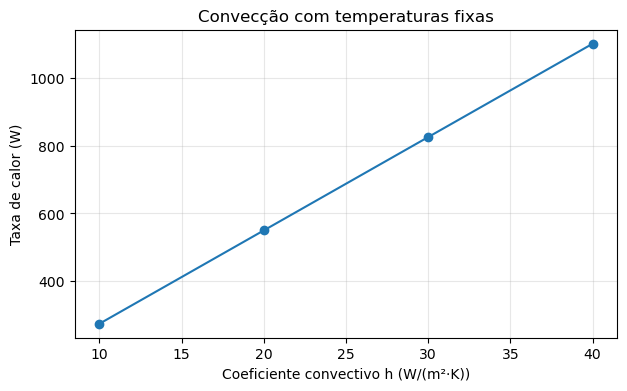

In [4]:
h = np.array([10., 20., 30., 40.])
Q_conv = h*0.5*(80-25)
print("h (W/m²K):", h)
print("Taxa convectiva (W):", Q_conv)
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(h, Q_conv, 'o-')
ax.set(xlabel='Coeficiente convectivo h (W/(m²·K))', ylabel='Taxa de calor (W)', title='Convecção com temperaturas fixas')
ax.grid(alpha=0.3)
plt.show()

<div id="secao-7" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">7. Radiação térmica e temperatura absoluta</div>

**Problema — Radiação de uma superfície.** A troca radiativa líquida entre uma superfície cinzenta pequena e um ambiente grande idealizado pode ser estimada por

$$\dot Q=\varepsilon\sigma A(T_s^4-T_{amb}^4),$$

com $\sigma=5{,}670374419\times10^{-8}$ W/(m²·K⁴). Para $\varepsilon=0{,}8$, $A=1$ m², $T_s=100$ °C e $T_{amb}=20$ °C, usamos **373,15 K** e **293,15 K**. Nunca substitua temperaturas em Celsius diretamente nessa expressão. O modelo desconsidera fatores de forma complexos e participação radiativa do meio.

In [5]:
sigma = 5.670374419e-8
emissividade, area_rad = 0.8, 1.0
Ts_K, Tamb_K = 100+273.15, 20+273.15
Q_rad = emissividade*sigma*area_rad*(Ts_K**4-Tamb_K**4)
print(f"Troca radiativa líquida: {Q_rad:.2f} W")
assert Q_rad > 0

Troca radiativa líquida: 544.49 W


<div id="secao-8" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">8. Balanço térmico de um fluido em escoamento</div>

**Problema — Aquecimento de um fluido em escoamento.** Em regime permanente, desprezando variações de energia cinética e potencial, trabalho de eixo e perdas não especificadas, o balanço simplificado é

$$\dot Q=\dot m c_p(T_{out}-T_{in}).$$

Se $\dot m=0{,}5$ kg/s, $c_p=4180$ J/(kg·K), $T_{in}=20$ °C e $T_{out}=30$ °C, então $\dot Q=0{,}5(4180)(10)=20\,900$ W. Trata-se de uma potência térmica, não de energia acumulada.

In [6]:
m_dot, cp = 0.5, 4180.0
Tin, Tout = 20.0, 30.0
Q_fluido = m_dot*cp*(Tout-Tin)
print(f"Potência de aquecimento: {Q_fluido/1000:.2f} kW")
assert np.isclose(Q_fluido, 20900)

Potência de aquecimento: 20.90 kW


<div id="secao-9" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">9. Trocadores de calor e diferença média logarítmica</div>

**Problema — Trocador de calor em contracorrente.** Para um trocador sem mudança de fase, a taxa de calor pode ser escrita como

$$\dot Q=UA\Delta T_{lm},\qquad \Delta T_{lm}=\frac{\Delta T_1-\Delta T_2}{\ln(\Delta T_1/\Delta T_2)}.$$

Para temperaturas de terminais de um exemplo em contracorrente, $T_{h,in}=100$ °C, $T_{h,out}=70$ °C, $T_{c,in}=20$ °C, $T_{c,out}=50$ °C, temos $\Delta T_1=100-50=50$ K e $\Delta T_2=70-20=50$ K. Quando são iguais, o limite matemático da DMLT é 50 K. Para $U=500$ W/(m²·K) e $A=2$ m², $\dot Q=50\,000$ W. Os valores de vazão e capacidade térmica dos fluidos devem ser compatíveis com essa taxa.

In [7]:
def dmlt(dt1, dt2):
    if dt1 <= 0 or dt2 <= 0:
        raise ValueError("Diferenças terminais devem ser positivas neste modelo.")
    if np.isclose(dt1, dt2, rtol=1e-10):
        return (dt1+dt2)/2
    return (dt1-dt2)/np.log(dt1/dt2)

DT1, DT2 = 100-50, 70-20
Q_trocador = 500*2*dmlt(DT1, DT2)
print(f"DMLT: {dmlt(DT1,DT2):.1f} K; potência: {Q_trocador/1000:.1f} kW")
assert np.isclose(Q_trocador, 50000)

DMLT: 50.0 K; potência: 50.0 kW


<div id="secao-10" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">10. Efetividade e método NTU</div>

**Problema — Estimativa por efetividade-NTU.** Quando as temperaturas de saída não são conhecidas, o método $\varepsilon$-NTU pode ser conveniente. Definimos $C_h=\dot m_hc_{p,h}$, $C_c=\dot m_cc_{p,c}$, $C_{min}=\min(C_h,C_c)$, $C_r=C_{min}/C_{max}$ e $NTU=UA/C_{min}$.

Para um trocador **em contracorrente**, com $C_r\ne1$,

$$\varepsilon=\frac{1-e^{-NTU(1-C_r)}}{1-C_re^{-NTU(1-C_r)}},\qquad \dot Q=\varepsilon C_{min}(T_{h,in}-T_{c,in}).$$

Tomando $C_h=2000$ W/K, $C_c=4000$ W/K, $UA=1000$ W/K, $T_{h,in}=100$ °C e $T_{c,in}=20$ °C, temos $C_r=0{,}5$, $NTU=0{,}5$ e $\varepsilon\approx0{,}3623$. Assim, $\dot Q\approx58{,}0$ kW. O modelo pressupõe operação em regime permanente e propriedades constantes.

In [8]:
Ch, Cc, UA = 2000.0, 4000.0, 1000.0
Cmin, Cmax = min(Ch,Cc), max(Ch,Cc)
Cr, NTU = Cmin/Cmax, UA/Cmin
z = np.exp(-NTU*(1-Cr))
epsilon = (1-z)/(1-Cr*z)
Q_ntu = epsilon*Cmin*(100-20)
Th_out = 100-Q_ntu/Ch
Tc_out = 20+Q_ntu/Cc
print(f"Efetividade: {epsilon:.4f}; Q: {Q_ntu/1000:.2f} kW")
print(f"Saídas: quente={Th_out:.2f} °C; fria={Tc_out:.2f} °C")
assert 0 < epsilon < 1 and Th_out > Tc_out

Efetividade: 0.3623; Q: 57.96 kW
Saídas: quente=71.02 °C; fria=34.49 °C


<div id="secao-11" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">11. Resfriamento transiente: modelo concentrado</div>

**Problema — Resfriamento transiente de um corpo.** Sob a hipótese de temperatura aproximadamente uniforme no sólido (modelo concentrado, usualmente justificado quando $Bi=hL_c/k_s<0{,}1$), o balanço de energia é

$$mc_p\frac{dT}{dt}=-hA(T-T_\infty).$$

Definindo $\alpha=hA/(mc_p)$, obtemos $dT/dt=-\alpha(T-T_\infty)$. Considere $m=2$ kg, $c_p=500$ J/(kg·K), $h=20$ W/(m²·K), $A=0{,}5$ m², $T_0=80$ °C e $T_\infty=20$ °C. Nesse caso, $\alpha=0{,}01$ s$^{-1}$ e a taxa inicial é $dT/dt=-0{,}6$ °C/s. Os dados não bastam, isoladamente, para verificar o número de Biot: geometria e condutividade do sólido ainda seriam necessárias.

In [9]:
massa, cp_solido, h_s, A_s = 2.0, 500.0, 20.0, 0.5
T0, T_amb = 80.0, 20.0
alpha = h_s*A_s/(massa*cp_solido)
print(f"Constante dinâmica: {alpha:.4f} 1/s")
print(f"Taxa inicial: {-alpha*(T0-T_amb):.3f} °C/s")

Constante dinâmica: 0.0100 1/s
Taxa inicial: -0.600 °C/s


<div id="secao-12" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">12. Solução analítica e método de Euler</div>

A solução analítica do modelo concentrado é

$$T(t)=T_\infty+(T_0-T_\infty)e^{-\alpha t}.$$

Para $t=10$ s, $T(10)=20+60e^{-0{,}1}\approx74{,}29$ °C. Pelo método de Euler explícito, com $\Delta t=10$ s, a primeira aproximação é $T_1=80+10[-0{,}01(80-20)]=74$ °C. O erro decorre da discretização temporal.

T(10 s) Euler: 74.000 °C; exata: 74.290 °C


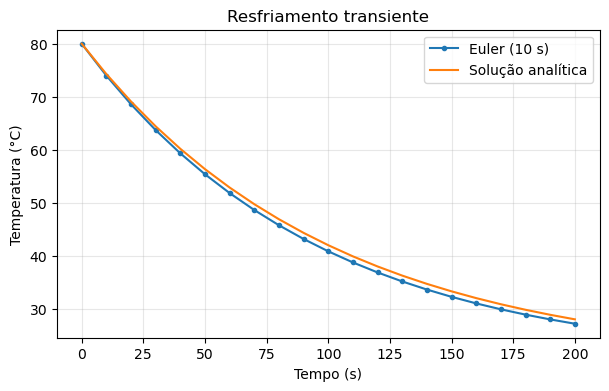

In [10]:
def euler_termico(dt, tf, alpha, T0, Tamb):
    passos = int(round(tf/dt))
    if dt <= 0 or not np.isclose(passos*dt,tf):
        raise ValueError("Passo temporal incompatível com o intervalo.")
    t = np.linspace(0,tf,passos+1)
    T = np.empty(passos+1); T[0]=T0
    for j in range(passos):
        T[j+1]=T[j]-dt*alpha*(T[j]-Tamb)
    return t,T

t_e,T_e = euler_termico(10.0, 200.0, alpha, T0, T_amb)
T_exata = T_amb+(T0-T_amb)*np.exp(-alpha*t_e)
print(f"T(10 s) Euler: {T_e[1]:.3f} °C; exata: {T_exata[1]:.3f} °C")
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(t_e,T_e,'o-',label='Euler (10 s)',markersize=3)
ax.plot(t_e,T_exata,'-',label='Solução analítica')
ax.set(xlabel='Tempo (s)',ylabel='Temperatura (°C)',title='Resfriamento transiente')
ax.legend();ax.grid(alpha=.3);plt.show()

<div id="secao-13" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">13. Simulação com solve_ivp e comparação</div>

Podemos comparar o algoritmo desenvolvido manualmente com um integrador adaptativo da biblioteca SciPy. O `solve_ivp` resolve o problema de valor inicial, mas não determina se as hipóteses físicas do modelo são adequadas. Para instalar SciPy, se necessário, use no terminal `python -m pip install scipy`.

A comparação com a solução analítica é uma forma de testar a implementação. A tolerância numérica do integrador deve ser escolhida em função da precisão necessária, e não apenas para obter mais casas decimais.

Erro máximo do solve_ivp frente à solução analítica: 1.432e-08 °C


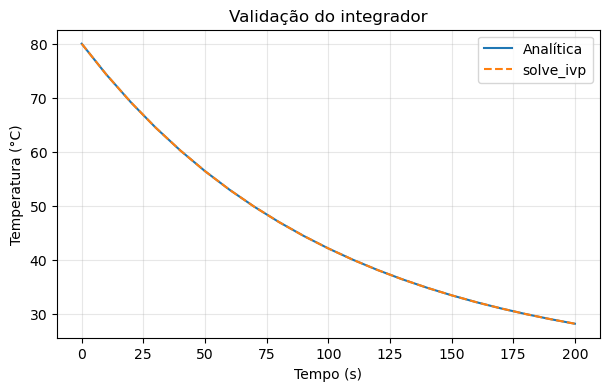

In [11]:
from scipy.integrate import solve_ivp

def rhs_termico(t, y):
    return [-alpha*(y[0]-T_amb)]

sol = solve_ivp(rhs_termico,(0,200),[T0],t_eval=t_e,rtol=1e-9,atol=1e-11)
assert sol.success
erro_max = np.max(np.abs(sol.y[0]-T_exata))
print(f"Erro máximo do solve_ivp frente à solução analítica: {erro_max:.3e} °C")
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(t_e,T_exata,label='Analítica')
ax.plot(sol.t,sol.y[0],'--',label='solve_ivp')
ax.set(xlabel='Tempo (s)',ylabel='Temperatura (°C)',title='Validação do integrador')
ax.legend();ax.grid(alpha=.3);plt.show()

<div id="secao-14" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">14. Condução transiente unidimensional: diferenças finitas</div>

**Problema — Condução transiente em uma barra.** Em uma barra homogênea com condução unidimensional e propriedades constantes, sem geração interna, a equação do calor é

$$\frac{\partial T}{\partial t}=a\frac{\partial^2T}{\partial x^2},\qquad a=\frac{k}{\rho c_p}.$$

Usando diferenças centrais no espaço e Euler no tempo, para pontos internos,

$$T_i^{n+1}=T_i^n+Fo\left(T_{i-1}^n-2T_i^n+T_{i+1}^n\right),\quad Fo=\frac{a\Delta t}{\Delta x^2}.$$

O esquema explícito unidimensional, com espaçamento uniforme, exige $Fo\le0{,}5$ para estabilidade. No exemplo, as extremidades são mantidas a 20 °C e o interior começa a 80 °C; o salto inicial junto às fronteiras é uma idealização matemática.

Fo = 0.500; dt = 1.2500 s; temperatura central final = 41.95 °C


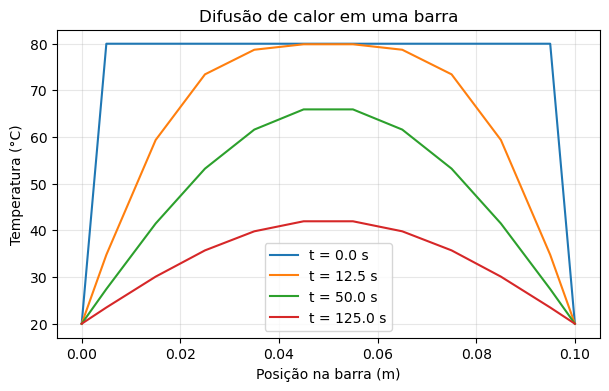

In [12]:
comprimento_barra = 0.10
nx=21
x=np.linspace(0,comprimento_barra,nx)
dx=x[1]-x[0]
difusividade=1.0e-5  # m²/s (valor ilustrativo)
dt_barra=0.5*dx**2/difusividade
Fo=difusividade*dt_barra/dx**2
T_barra=np.full(nx,80.0);T_barra[[0,-1]]=20.0
perfis=[T_barra.copy()]
for passo in range(100):
    novo=T_barra.copy()
    novo[1:-1]=T_barra[1:-1]+Fo*(T_barra[:-2]-2*T_barra[1:-1]+T_barra[2:])
    T_barra=novo
    if passo+1 in (10,40,100):perfis.append(T_barra.copy())
print(f"Fo = {Fo:.3f}; dt = {dt_barra:.4f} s; temperatura central final = {T_barra[nx//2]:.2f} °C")
assert Fo<=0.5 and np.all(T_barra>=20-1e-8) and np.all(T_barra<=80+1e-8)
fig,ax=plt.subplots(figsize=(7,4))
for perfil,passo in zip(perfis,[0,10,40,100]):
    ax.plot(x,perfil,label=f't = {passo*dt_barra:.1f} s')
ax.set(xlabel='Posição na barra (m)',ylabel='Temperatura (°C)',title='Difusão de calor em uma barra')
ax.legend();ax.grid(alpha=.3);plt.show()

<div id="secao-15" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">15. Sensibilidade térmica e interpretação de gráficos</div>

**Problema — Espessura de isolamento.** Para uma parede plana com temperaturas de face fixas, $\dot Q=kA\Delta T/L$. Assim, $\dot Q$ é inversamente proporcional à espessura. Essa conclusão é específica da geometria e das condições de contorno escolhidas; em tubulações com convecção externa, o comportamento pode ser diferente.

Vamos variar $L$ entre 0,02 e 0,20 m, mantendo $k=0{,}8$ W/(m·K), $A=2$ m² e $\Delta T=60$ K. Para $L=0{,}10$ m, o valor de referência continua sendo 960 W.

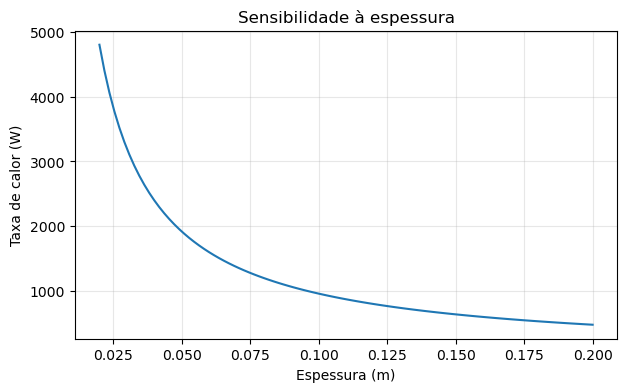

Q para L=0,10 m: 960.0 W


In [13]:
L_vetor=np.linspace(0.02,0.20,100)
Q_vetor=0.8*2.0*60.0/L_vetor
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(L_vetor,Q_vetor)
ax.set(xlabel='Espessura (m)',ylabel='Taxa de calor (W)',title='Sensibilidade à espessura')
ax.grid(alpha=.3);plt.show()
print(f"Q para L=0,10 m: {0.8*2*60/0.10:.1f} W")

<div id="secao-16" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">16. Verificação física e limitações dos modelos</div>

Antes de aceitar resultados, verifique: **(i)** unidades e temperatura absoluta quando necessária; **(ii)** sentido físico do fluxo de calor; **(iii)** conservação de energia; **(iv)** adequação de propriedades e coeficientes; **(v)** hipóteses de regime permanente ou transiente; **(vi)** convergência de malha e passo temporal.

Em um trocador adiabático em relação ao ambiente, a potência perdida pelo fluido quente deve coincidir, em módulo, com a potência recebida pelo fluido frio. A diferença entre valores calculados pode revelar erro de unidades, medição, arredondamento ou hipótese inadequada.

Para o modelo concentrado, é indispensável avaliar o número de Biot antes de tratar a temperatura do sólido como uniforme. Para diferenças finitas explícitas, a condição de estabilidade não assegura, sozinha, precisão suficiente.

In [14]:
# Verificação de conservação no exemplo NTU
Q_quente = Ch*(100-Th_out)
Q_frio = Cc*(Tc_out-20)
print(f"Calor perdido pelo quente: {Q_quente/1000:.3f} kW")
print(f"Calor ganho pelo frio: {Q_frio/1000:.3f} kW")
assert np.isclose(Q_quente,Q_frio,rtol=1e-10)
print("Balanço de energia satisfeito dentro da tolerância numérica.")

Calor perdido pelo quente: 57.962 kW
Calor ganho pelo frio: 57.962 kW
Balanço de energia satisfeito dentro da tolerância numérica.


<div id="secao-17" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">17. Exercícios de consolidação</div>

**Exercício 1 — Condução.** Uma parede possui $k=1{,}2$ W/(m·K), área de 3 m², espessura de 0,15 m e temperaturas de face de 90 e 30 °C. Calcule manualmente a taxa de calor e confirme em Python.

**Exercício 2 — Resistências térmicas.** Compare duas paredes compostas por camadas com diferentes espessuras e condutividades. Explique qual oferece maior resistência e por quê.

**Exercício 3 — Condução radial.** Calcule a perda de calor por uma camada cilíndrica de isolamento e analise o efeito do raio externo, mantendo fixas as temperaturas das superfícies.

**Exercício 4 — Convecção.** Para uma superfície a 70 °C em ambiente a 25 °C, avalie a taxa de calor para $h=5,10,20,40$ W/(m²·K), com área de 0,8 m².

**Exercício 5 — Radiação.** Calcule a troca radiativa líquida de uma superfície com emissividade 0,9, área 0,5 m² e temperaturas de 120 °C e 25 °C. Justifique a conversão para kelvin.

**Exercício 6 — Balanço em fluido.** Um fluido com $\dot m=0{,}25$ kg/s e $c_p=4000$ J/(kg·K) recebe 12 kW. Calcule sua elevação de temperatura e discuta as hipóteses.

**Exercício 7 — Trocadores.** Determine a DMLT para diferenças terminais de 60 e 30 K; estime $\dot Q$ com $U=300$ W/(m²·K) e $A=4$ m².

**Exercício 8 — Dinâmica.** Para $dT/dt=-0{,}02(T-25)$, $T_0=85$ °C, simule 120 s com Euler usando passos de 10, 5 e 1 s. Compare com a solução analítica e discuta o erro.

**Desafio integrador — Condução transiente.** Modifique o modelo de diferenças finitas da barra para diferentes números de pontos. Escolha $\Delta t$ respeitando $Fo\le0{,}5$ e compare perfis no mesmo instante físico, discutindo convergência espacial e temporal.

<div id="secao-18" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">18. Conclusões</div>

A transferência de calor reúne mecanismos físicos distintos, mas todos exigem a mesma disciplina de modelagem: identificar o sistema, escrever os balanços, definir hipóteses, calcular, verificar e interpretar. Com Python, conseguimos explorar variações paramétricas e modelos transientes; com a Engenharia, decidimos se as respostas têm significado.

O próximo notebook da coleção tratará de Instrumentação e Sinais, retomando medições, calibração e processamento de dados.

<div style="text-align: center; font-size: 12px; color: gray; margin-top: 40px; padding-top: 15px; border-top: 1px solid #dddddd;">
Material desenvolvido pelo Grupo de Pesquisas em Modelagem Computacional da UESC.<br>
© 2026 — Todos os direitos reservados. Uso comercial somente mediante autorização.
</div>